# 🚗 3D LiDAR-Based Bird's-Eye View (BEV) Object Detection via BEVFusion
### Multi-Task Multi-Sensor 3D Perception Framework on nuScenes & KITTI
---

## 📋 System & Environment Specifications

| Component | Verified Environment Specification |
| :--- | :--- |
| **Operating System** | **Ubuntu 22.04.4 LTS (Jammy Jellyfish)** |
| **Python Runtime** | **Python 3.10.22** (Packaged by `conda-forge` via Pixi) |
| **Python Executable** | `/content/.pixi/envs/default/bin/python` |
| **GPU Hardware** | **NVIDIA Tesla T4 (15 GB VRAM)** |
| **CUDA Toolkit / nvcc** | **CUDA 11.8 (V11.8.89)** |
| **PyTorch Suite** | `torch==2.1.2+cu118` \| `torchvision==0.16.2+cu118` \| `torchaudio==2.1.2+cu118` |
| **MMCV Ecosystem** | `mmcv==2.1.0` (Compiled with CUDA 11.8 & GCC 9.3) \| `mmengine==0.10.7` |
| **MMDetection3D** | `mmdet3d==1.4.0` (dev-1.x with custom BEVFusion extensions) |
| **Numerical Libraries**| `numpy==1.26.4` \| `pandas==2.2.2` \| `scipy==1.13.1` |
| **Compilers** | Host GCC: `14.4.0` \| MMCV Compiler: `GCC 9.3` \| NVCC: `11.8` |

---
## 📑 Workflow Overview
1. **System & Toolchain Setup**: Initialize Python 3.10 via Pixi/CondaColab, install CUDA 11.8 Toolkit.
2. **Framework Installation**: Install PyTorch 2.1.2 (cu118), MMCV 2.1.0, MMEngine, and dependencies.
3. **Repository & Patching**: Clone upstream MMDetection3D and apply project custom patches.
4. **CUDA Ops Compilation**: Compile BEVFusion's custom `bev_pool` and `voxel_layer` operators.
5. **Model & Checkpoints**: Download BEVFusion pretrained weights and fix `spconv 1.x` $\to$ `2.x` tensor mismatch.
6. **Inference & Visualization**: Run 10-frame demo, Full nuScenes Mini 404-frame batch inference, and render Full HD 360° Surround + BEV Video/GIF.

## 1. ⚙️ Python 3.10 & Pixi Environment Initialization
Set up an isolated Python 3.10 environment using `condacolab` / `pixi` to ensure strict ABI compatibility with MMCV and sparse convolution libraries.

In [1]:
# Check base system Python version
!python --version

Python 3.12.12


In [2]:
# Install condacolab with pre-release support for isolated Python 3.10 environment
!pip install -q --pre condacolab

In [3]:
# Initialize CondaColab / Pixi environment targeting Python 3.10
import condacolab
condacolab.install(python_version="3.10")

📝 Writing pixi.toml...
📦 Installing...
✨ Last touches...
⏲ Done in 0:00:24
✅ Done! Restarting kernel...
ℹ️ [INFO]
  Once the session reconnects, you will be running a new Python v3.10.
  You can install new packages by running pixi in new cells like this:
    !pixi add <name>


In [2]:
# Verify activated Python 3.10 environment and binary executable path
import sys

print("Python Version:", sys.version)
print("Executable Path:", sys.executable)

Python Version: 3.10.22 | packaged by conda-forge | (main, Oct  6 2026, 23:02:24) [GCC 14.4.0]
Executable Path: /content/.pixi/envs/default/bin/python


## 2. 🚀 CUDA 11.8 Toolkit Installation & GPU Configuration
Install the official NVIDIA CUDA 11.8 toolkit (`cuda-toolkit-11-8`) on Ubuntu 22.04 LTS to match MMCV and PyTorch 2.1.2 CUDA requirements.
- Note: If your Ubuntu is Ubuntu >= 23.04 (23.04 Not support CUDA 11.8), you can change your runtime version to 2025.10 (https://research.google.com/colaboratory/runtime-version-faq.html#2025.10)

In [3]:
# Inspect host GPU details, NVIDIA driver version, and default CUDA paths
!nvcc --version
!nvidia-smi
!ls -la /usr/local | grep cuda

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Thu_Jun__6_02:18:23_PDT_2024
Cuda compilation tools, release 12.5, V12.5.82
Build cuda_12.5.r12.5/compiler.34385749_0
Mon Nov  9 08:55:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8       

In [4]:
# Verify Ubuntu 22.04 LTS release compatibility for CUDA 11.8 repository
!cat /etc/os-release

PRETTY_NAME="Ubuntu 22.04.4 LTS"
NAME="Ubuntu"
VERSION_ID="22.04"
VERSION="22.04.4 LTS (Jammy Jellyfish)"
VERSION_CODENAME=jammy
ID=ubuntu
ID_LIKE=debian
HOME_URL="https://www.ubuntu.com/"
SUPPORT_URL="https://help.ubuntu.com/"
BUG_REPORT_URL="https://bugs.launchpad.net/ubuntu/"
PRIVACY_POLICY_URL="https://www.ubuntu.com/legal/terms-and-policies/privacy-policy"
UBUNTU_CODENAME=jammy


In [5]:
# # Add NVIDIA Ubuntu 22.04 repository keyring and refresh apt cache
# !wget -q https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64/cuda-keyring_1.1-1_all.deb
# !dpkg -i cuda-keyring_1.1-1_all.deb
# !apt-get update -qq

(Reading database ... 126675 files and directories currently installed.)
Preparing to unpack cuda-keyring_1.1-1_all.deb ...
Unpacking cuda-keyring (1.1-1) over (1.1-1) ...
Setting up cuda-keyring (1.1-1) ...
W: An error occurred during the signature verification. The repository is not updated and the previous index files will be used. GPG error: https://cli.github.com/packages stable InRelease: The following signatures couldn't be verified because the public key is not available: NO_PUBKEY 5612B36462313325
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://cli.github.com/packages/dists/stable/InRelease  The following signatures couldn't be verified because the public key is not available: NO_PUBKEY 5612B36462313325
W: Some index files failed to download. They have been ignored, or old ones used instead.


In [6]:
# Check package availability for cuda-toolkit-11-8
!apt-cache policy cuda-toolkit-11-8

cuda-toolkit-11-8:
  Installed: (none)
  Candidate: 11.8.0-1
  Version table:
     11.8.0-1 600
        600 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages


In [7]:
# Install CUDA 11.8 compiler, nvcc, cuobjdump, headers, and development libraries
!apt-get install -y cuda-toolkit-11-8

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  cuda-cccl-11-8 cuda-command-line-tools-11-8 cuda-compiler-11-8
  cuda-cudart-11-8 cuda-cudart-dev-11-8 cuda-cuobjdump-11-8 cuda-cupti-11-8
  cuda-cupti-dev-11-8 cuda-cuxxfilt-11-8 cuda-documentation-11-8
  cuda-driver-dev-11-8 cuda-gdb-11-8 cuda-libraries-11-8
  cuda-libraries-dev-11-8 cuda-memcheck-11-8 cuda-nsight-11-8
  cuda-nsight-compute-11-8 cuda-nsight-systems-11-8 cuda-nvcc-11-8
  cuda-nvdisasm-11-8 cuda-nvml-dev-11-8 cuda-nvprof-11-8 cuda-nvprune-11-8
  cuda-nvrtc-11-8 cuda-nvrtc-dev-11-8 cuda-nvtx-11-8 cuda-nvvp-11-8
  cuda-profiler-api-11-8 cuda-sanitizer-11-8 cuda-toolkit-11-8-config-common
  cuda-toolkit-11-config-common cuda-tools-11-8 cuda-visual-tools-11-8
  default-jre default-jre-headless fonts-dejavu-core fonts-dejavu-extra
  gds-tools-11-8 libatk-wrapper-java libatk-wrapper-java-jni libcublas-11-8
  libcublas-dev-11-

In [12]:
# Export CUDA_HOME, PATH, and LD_LIBRARY_PATH environment variables for CUDA 11.8
import os

os.environ["CUDA_HOME"] = "/usr/local/cuda-11.8"
os.environ["PATH"] = "/usr/local/cuda-11.8/bin:" + os.environ["PATH"]
os.environ["LD_LIBRARY_PATH"] = (
    "/usr/local/cuda-11.8/lib64:"
    + os.environ.get("LD_LIBRARY_PATH", "")
)

In [13]:
# Verify that nvcc is active and targeting CUDA 11.8 (V11.8.89)
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2022 NVIDIA Corporation
Built on Wed_Sep_21_10:33:58_PDT_2022
Cuda compilation tools, release 11.8, V11.8.89
Build cuda_11.8.r11.8/compiler.31833905_0


In [ ]:
# [Checkpoint] Environment variables active - restart runtime if prompted
# RESTART RUNTIME (if necessary)

## 3. 📦 Deep Learning Frameworks: PyTorch 2.1.2 (cu118) & MMCV 2.1.0
Install `torch==2.1.2+cu118`, prebuilt `mmcv==2.1.0` with full CUDA acceleration, and pinned scientific computing packages (`numpy==1.26.4`, `pandas==2.2.2`).

In [10]:
# Add pip to the Pixi environment
!pixi add pip

✔ pip is already a dependency
  Run `pixi upgrade pip` to get the newest compatible version


In [11]:
# 1. Install PyTorch 2.1.2 with CUDA 11.8 support
!pixi run python -m pip install torch==2.1.2 torchvision==0.16.2 torchaudio==2.1.2 --index-url https://download.pytorch.org/whl/cu118

# 2. Pin NumPy 1.26.4 and Pandas 2.2.2 for binary compatibility with compiled ops
!pixi run python -m pip install \
    --force-reinstall \
    --no-cache-dir \
    --no-deps \
    numpy==1.26.4 pandas==2.2.2
!pixi add "scipy==1.13.1"

Looking in indexes: https://download.pytorch.org/whl/cu118
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 GB 12.6 MB/s  0:00:45
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 100.4 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 113.9 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.2/89.2 MB 68.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 69.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 139.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 23.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [torchaudio]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 182.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 155.3 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.3.3
    Uninstalling pandas-2.3.3:
      Successfully uninstalled pandas-2.3.3
  Attempting uninstall: numpy
    Found

In [ ]:
# [Checkpoint] PyTorch installation complete
# RESTART RUNTIME (if necessary)

In [1]:
# 3. Install MMEngine
!pixi run python -m pip install mmengine

# 4. Install MMCV 2.1.0 prebuilt wheel with CUDA 11.8 operators
!pixi run python -m pip install mmcv==2.1.0 \
    -f https://download.openmmlab.com/mmcv/dist/cu118/torch2.1.0/index.html

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 71.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 164.3 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [mmengine]
Looking in links: https://download.openmmlab.com/mmcv/dist/cu118/torch2.1.0/index.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.3/99.3 MB 17.0 MB/s  0:00:05


In [14]:
# Fix CXXABI_1.3.15 dynamic linker conflict by linking Pixi libstdc++ into system library
!cp /content/.pixi/envs/default/lib/libstdc++.so.6 /usr/lib/x86_64-linux-gnu/libstdc++.so.6

## 4. 📂 Repository Setup & Dependency Installation
Clone the BEVFusion 3D object detection project repository and install all auxiliary requirements (Open3D, OpenCV, nuscenes-devkit).

In [3]:
# Clone the primary project repository
!git clone https://github.com/tranphat1506/3D-LiDAR-BEVFusion-MMDetection3D-V2.git

Cloning into '3D-LiDAR-BEVFusion-MMDetection3D-V2'...
remote: Enumerating objects: 74, done.
remote: Counting objects: 100% (74/74), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 74 (delta 2), reused 74 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (74/74), 28.70 MiB | 20.58 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [4]:
%cd /content/3D-LiDAR-BEVFusion-MMDetection3D-V2

# Install remaining dependencies from requirements.txt
!pixi run python -m pip install -r requirements.txt

/content/3D-LiDAR-BEVFusion-MMDetection3D-V2
INFO: pip is looking at multiple versions of plyfile to determine which version is compatible with other requirements. This could take a while.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 175.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 MB 62.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.1/49.1 MB 86.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 102.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 47.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 MB 20.3 MB/s  0:00:14
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 140.3 MB/s  0:00:00
   ━━━━━

In [15]:
# Comprehensive Toolchain & Library Verification
import sys
import numpy as np
import pandas as pd
import torch
import mmcv
import mmengine

print("=" * 60)
print("VERIFIED ENVIRONMENT SPECIFICATIONS:")
print(f"  Python:     {sys.version.split()[0]} ({sys.executable})")
print(f"  NumPy:      {np.__version__}")
print(f"  Pandas:     {pd.__version__}")
print(f"  PyTorch:    {torch.__version__}")
print(f"  CUDA (PyT): {torch.version.cuda} | GPU Available: {torch.cuda.is_available()}")
print(f"  GPU Name:   {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A'}")
print(f"  MMCV:       {mmcv.__version__}")
print(f"  MMEngine:   {mmengine.__version__}")

# Check MMCV compiled CUDA operators
from mmcv.ops import get_compiler_version, get_compiling_cuda_version
print(f"  Compiler:   {get_compiler_version()}")
print(f"  MMCV CUDA:  {get_compiling_cuda_version()}")
print("=" * 60)

VERIFIED ENVIRONMENT SPECIFICATIONS:
  Python:     3.10.22 (/content/.pixi/envs/default/bin/python)
  NumPy:      1.26.4
  Pandas:     2.2.2
  PyTorch:    2.1.2+cu118
  CUDA (PyT): 11.8 | GPU Available: True
  GPU Name:   Tesla T4
  MMCV:       2.1.0
  MMEngine:   0.10.7
  Compiler:   GCC 9.3
  MMCV CUDA:  11.8


## 5. 🛠️ Upstream MMDetection3D Integration & Custom Patching
Clone OpenMMLab's `mmdetection3d` (`dev-1.x`), apply project patches from `custom_changes/` (inferencer fixes, nuScenes metric patches), and install in development mode.

In [10]:
%cd /content/3D-LiDAR-BEVFusion-MMDetection3D-V2

/content/3D-LiDAR-BEVFusion-MMDetection3D-V2


In [8]:
# Create external folder and clone mmdetection3d (dev-1.x branch)
!mkdir -p external
!git clone -b dev-1.x https://github.com/open-mmlab/mmdetection3d.git external/mmdetection3d

fatal: destination path 'external/mmdetection3d' already exists and is not an empty directory.


In [9]:
# Apply custom bugfixes and configurations from custom_changes/ into external/mmdetection3d/
!cp -r custom_changes/* external/mmdetection3d/

In [5]:
# Again because when you restart runtime CUDA will switch to newest version
import os

os.environ["CUDA_HOME"] = "/usr/local/cuda-11.8"
os.environ["PATH"] = "/usr/local/cuda-11.8/bin:" + os.environ["PATH"]
os.environ["LD_LIBRARY_PATH"] = (
    "/usr/local/cuda-11.8/lib64:"
    + os.environ.get("LD_LIBRARY_PATH", "")
)

In [16]:
# Verify nvcc path and version prior to compilation
!which nvcc
!nvcc --version

/usr/local/cuda-11.8/bin/nvcc
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2022 NVIDIA Corporation
Built on Wed_Sep_21_10:33:58_PDT_2022
Cuda compilation tools, release 11.8, V11.8.89
Build cuda_11.8.r11.8/compiler.31833905_0


In [17]:
# Install patched mmdet3d in development mode
%cd external/mmdetection3d/
!pixi run python setup.py develop
%cd ../..

/content/3D-LiDAR-BEVFusion-MMDetection3D-V2/external/mmdetection3d
running develop
/content/.pixi/envs/default/lib/python3.10/site-packages/setuptools/command/easy_install.py:156: EasyInstallDeprecationWarning: easy_install command is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
/content/.pixi/envs/default/lib/python3.10/site-packages/setuptools/command/install.py:34: SetuptoolsDeprecationWarning: setup.py install is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
running egg_info
writing manifest file 'mmdet3d.egg-info/SOURCES.txt'
/content/.pixi/envs/default/lib/python3.10/site-packages/torch/utils/cpp_extension.py:502: UserWarning: Attempted to use ninja as the BuildExtension backend but we could not find ninja.. Falling back to using the slow distutils backend.
  warnings.warn(msg.format('we could not find ninja.'))
running build_ext
/content/3D-LiDAR-BEVFusion-MMDetection3D-V2


## 6. ⚡ Compile BEVFusion Custom CUDA Operators
Compile BEVFusion's custom GPU kernels (`bev_pool_ext` and `voxel_layer`) using NVCC 11.8 for accelerated multi-sensor BEV feature aggregation.

In [18]:
# Compile BEVFusion CUDA extensions in projects/BEVFusion
%cd external/mmdetection3d/projects/BEVFusion
!pixi run python setup.py develop
%cd /content/3D-LiDAR-BEVFusion-MMDetection3D-V2

/content/3D-LiDAR-BEVFusion-MMDetection3D-V2/external/mmdetection3d/projects/BEVFusion
running develop
/content/.pixi/envs/default/lib/python3.10/site-packages/setuptools/command/easy_install.py:156: EasyInstallDeprecationWarning: easy_install command is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
/content/.pixi/envs/default/lib/python3.10/site-packages/setuptools/command/install.py:34: SetuptoolsDeprecationWarning: setup.py install is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
running egg_info
/content/.pixi/envs/default/lib/python3.10/site-packages/torch/utils/cpp_extension.py:502: UserWarning: Attempted to use ninja as the BuildExtension backend but we could not find ninja.. Falling back to using the slow distutils backend.
  warnings.warn(msg.format('we could not find ninja.'))
writing manifest file 'bev_pool.egg-info/SOURCES.txt'
running build_ext
/content/.pixi/envs/default/lib/python3.10/site-packages/torch

In [2]:
# Add BEVFusion project path to sys.path
import sys

BEVFUSION_ROOT = (
    "/content/3D-LiDAR-BEVFusion-MMDetection3D-V2"
    "/external/mmdetection3d/projects/BEVFusion"
)

if BEVFUSION_ROOT not in sys.path:
    sys.path.insert(0, BEVFUSION_ROOT)

In [19]:
# Verify BEVFusion CUDA operators and mmdet3d inferencer availability
from bevfusion.ops.bev_pool import bev_pool_ext
from bevfusion.ops.voxel import voxel_layer
from mmdet3d.apis import LidarDet3DInferencer
from mmengine.config import Config

print("bev_pool_ext: OK")
print("voxel_layer: OK")

bev_pool_ext: OK
voxel_layer: OK


## 7. 📥 Download Pretrained Checkpoint & Fix Tensor Layout
Download official OpenMMLab BEVFusion pretrained weights and run `fix_bevfusion_checkpoint.py` to transpose sparse convolution tensor layouts from `spconv 1.x` (`[out, D, H, W, in]`) to `spconv 2.x` (`[D, H, W, in, out]`).

In [20]:
# Return to repository root directory
%cd /content/3D-LiDAR-BEVFusion-MMDetection3D-V2

/content/3D-LiDAR-BEVFusion-MMDetection3D-V2


In [21]:
# Create checkpoint folder and download official BEVFusion weights
!mkdir -p checkpoints/bevfusion_lidar
!wget -O checkpoints/bevfusion_lidar/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933.pth \
  https://download.openmmlab.com/mmdetection3d/v1.1.0_models/bevfusion/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933.pth

--2026-11-09 09:36:18--  https://download.openmmlab.com/mmdetection3d/v1.1.0_models/bevfusion/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933.pth
Resolving download.openmmlab.com (download.openmmlab.com)... 163.181.87.68, 163.181.87.87, 163.181.87.71, ...
Connecting to download.openmmlab.com (download.openmmlab.com)|163.181.87.68|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 46332893 (44M) [application/octet-stream]
Saving to: ‘checkpoints/bevfusion_lidar/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933.pth’

checkpoints/bevfusi 100%[===================>]  44.19M  26.7MB/s    in 1.7s    

2026-11-09 09:36:20 (26.7 MB/s) - ‘checkpoints/bevfusion_lidar/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933.pth’ saved [46332893/46332893]



In [22]:
# Transpose sparse convolution weights to match spconv 2.x layout
!pixi run python fix_bevfusion_checkpoint.py \
  --input checkpoints/bevfusion_lidar/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933.pth \
  --output checkpoints/bevfusion_lidar/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933_fixed.pth

Loading checkpoint from checkpoints/bevfusion_lidar/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933.pth...
Found 306 parameters in checkpoint
Found 21 spconv weight layers to fix:
  pts_middle_encoder.conv_input.0.weight: torch.Size([16, 3, 3, 3, 5])
  pts_middle_encoder.encoder_layers.encoder_layer1.0.conv1.weight: torch.Size([16, 3, 3, 3, 16])
  pts_middle_encoder.encoder_layers.encoder_layer1.0.conv2.weight: torch.Size([16, 3, 3, 3, 16])
  pts_middle_encoder.encoder_layers.encoder_layer1.1.conv1.weight: torch.Size([16, 3, 3, 3, 16])
  pts_middle_encoder.encoder_layers.encoder_layer1.1.conv2.weight: torch.Size([16, 3, 3, 3, 16])
  pts_middle_encoder.encoder_layers.encoder_layer1.2.0.weight: torch.Size([32, 3, 3, 3, 16])
  pts_middle_encoder.encoder_layers.encoder_layer2.0.conv1.weight: torch.Size([32, 3, 3, 3, 32])
  pts_middle_encoder.encoder_layers.encoder_layer2.0.conv2.weight: torch.Size([32, 3, 3, 3, 32])
  pts_middle_encoder.encoder_layers.encoder_layer2

## 8. 🎯 Quick 10-Frame Demo Inference & BEV Visualizations
Execute batch 3D LiDAR object detection on the 10 included demo samples and generate high-resolution Bird's-Eye View (BEV) visualizations.

In [23]:
# Run automated inference on 10 demo point cloud samples
!pixi run python setup_demo.py

Using device: cuda:0
Using 10 sample files found in /content/3D-LiDAR-BEVFusion-MMDetection3D-V2/demo
Loading config from /content/3D-LiDAR-BEVFusion-MMDetection3D-V2/external/mmdetection3d/projects/BEVFusion/configs/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d.py
Loading weights from /content/3D-LiDAR-BEVFusion-MMDetection3D-V2/checkpoints/bevfusion_lidar/bevfusion_lidar_voxel0075_second_secfpn_8xb4-cyclic-20e_nus-3d-2628f933_fixed.pth
/content/.pixi/envs/default/lib/python3.10/site-packages/mmdet/models/task_modules/builder.py:17: UserWarning: ``build_sampler`` would be deprecated soon, please use ``mmdet.registry.TASK_UTILS.build()`` 
  warnings.warn('``build_sampler`` would be deprecated soon, please use '
/content/.pixi/envs/default/lib/python3.10/site-packages/mmdet/models/task_modules/builder.py:39: UserWarning: ``build_assigner`` would be deprecated soon, please use ``mmdet.registry.TASK_UTILS.build()`` 
  warnings.warn('``build_assigner`` would be deprecated 

In [24]:
# Render BEV visualizations (depth-colored LiDAR points + 3D bounding boxes)
!pixi run python visualize_demo.py

Visualizing 10 files with enhanced style...
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151603547590.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151604048025.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151604547893.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151605047769.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151605548192.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151606048630.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151606549066.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151607048933.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151607548824.pcd.bin.png
Saved n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151608048151.pcd.bin.png
Done visualizing. Total rendered: 10 images.


Tìm thấy 10 hình ảnh kết quả. Bắt đầu hiển thị:

[1/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151603547590.pcd.bin.png


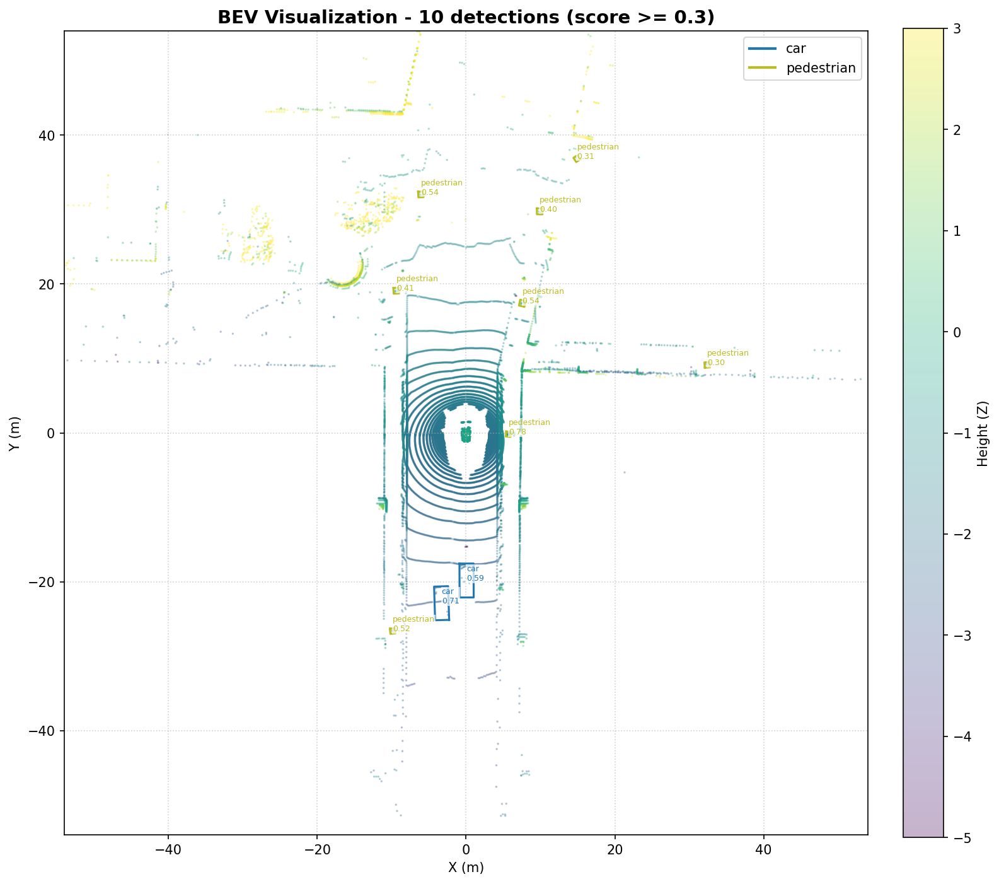


[2/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151604048025.pcd.bin.png


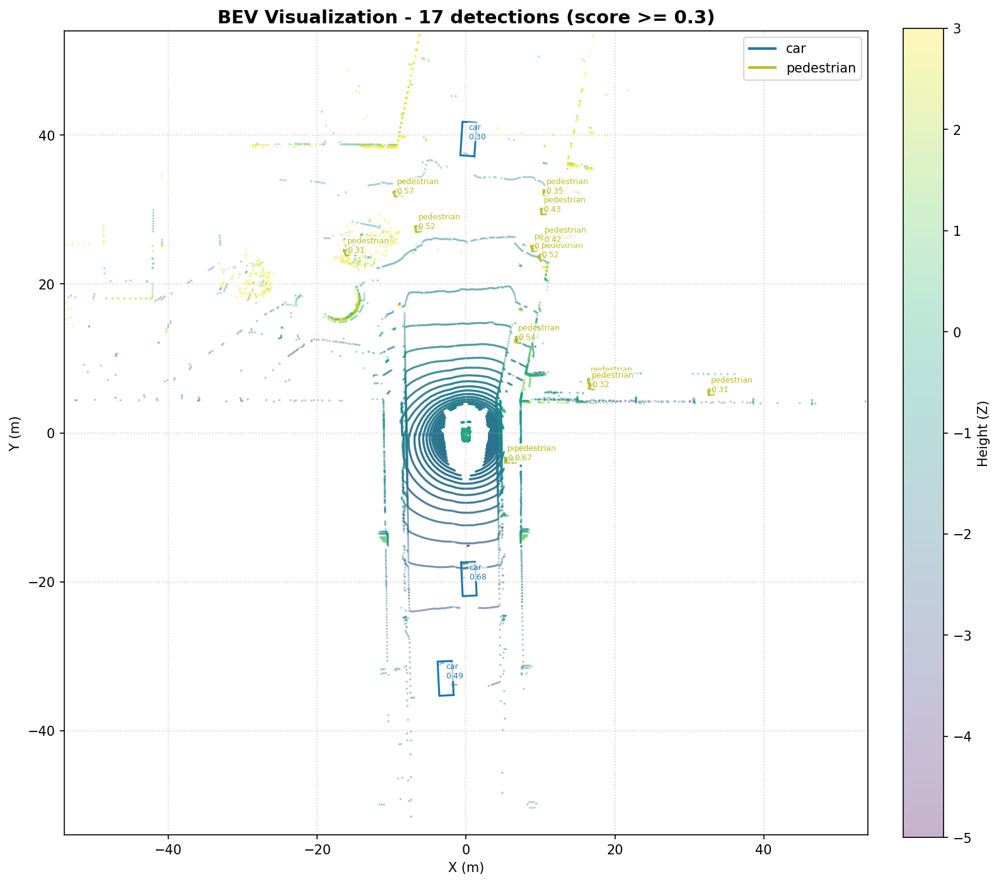


[3/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151604547893.pcd.bin.png


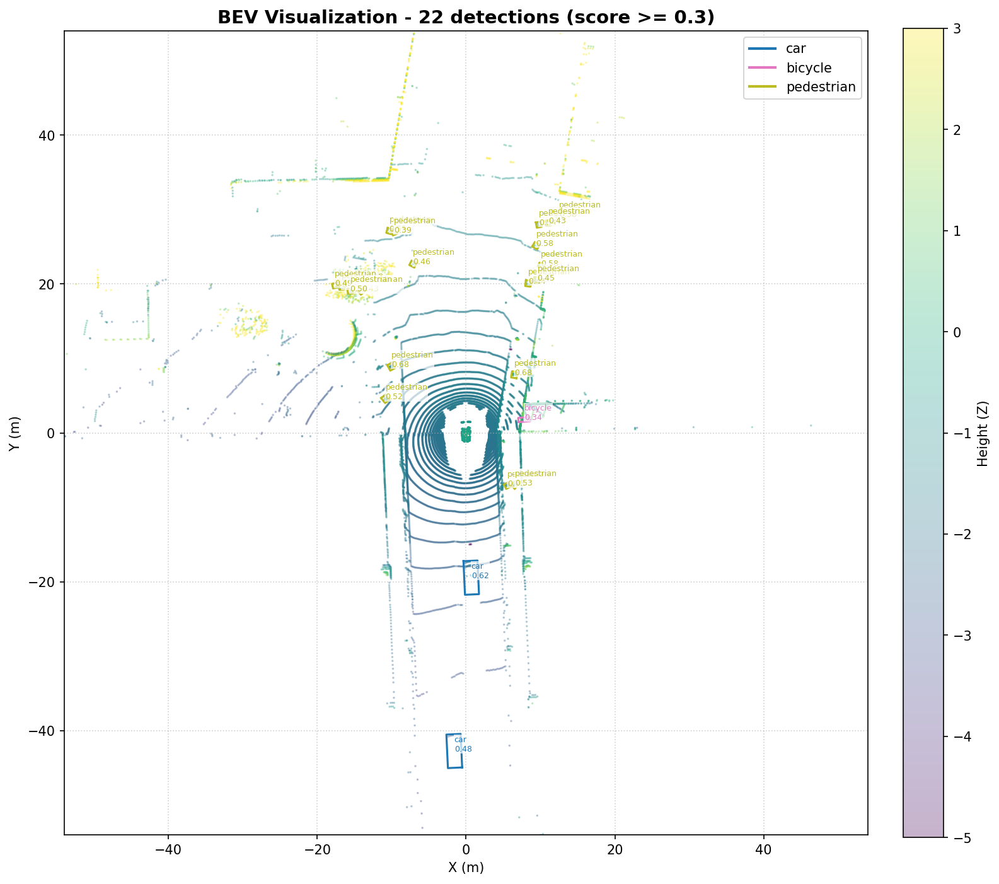


[4/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151605047769.pcd.bin.png


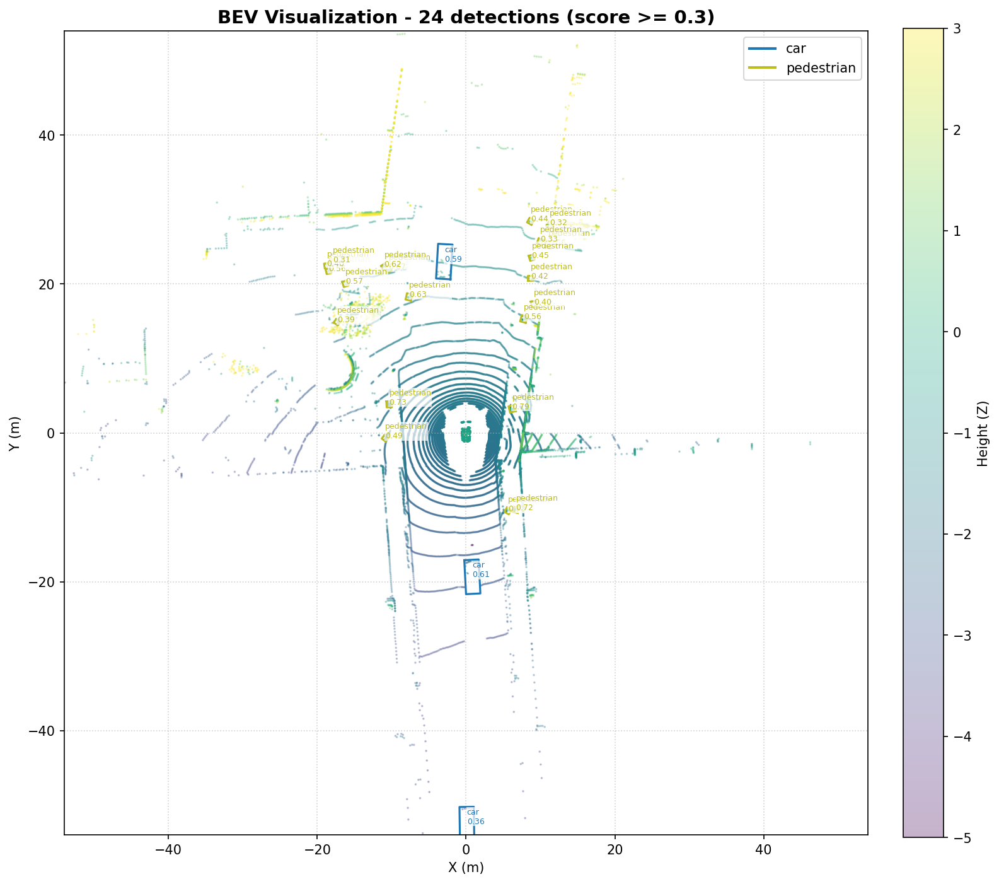


[5/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151605548192.pcd.bin.png


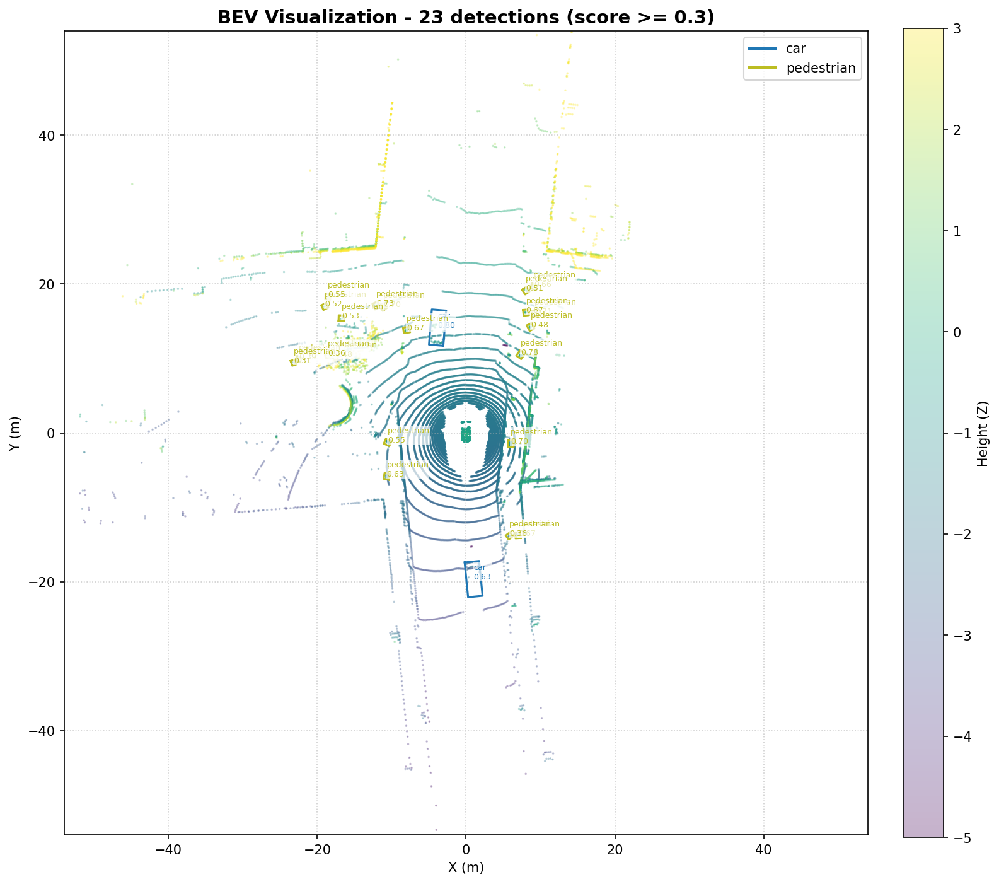


[6/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151606048630.pcd.bin.png


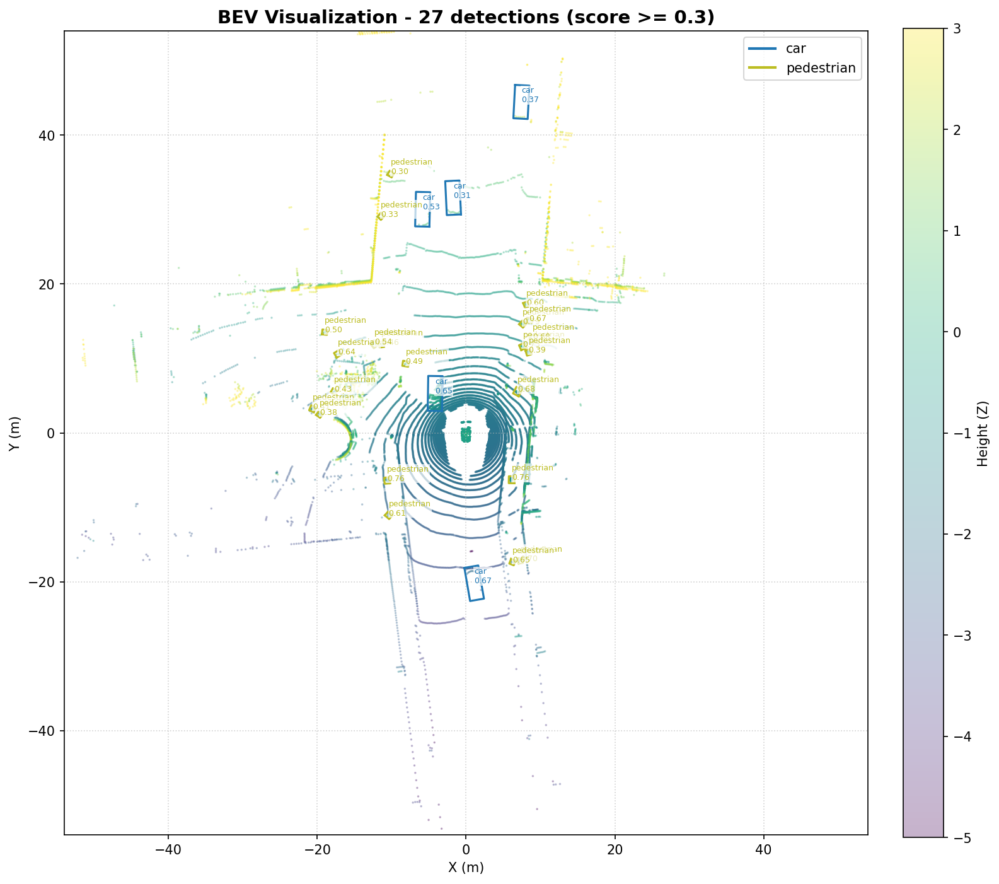


[7/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151606549066.pcd.bin.png


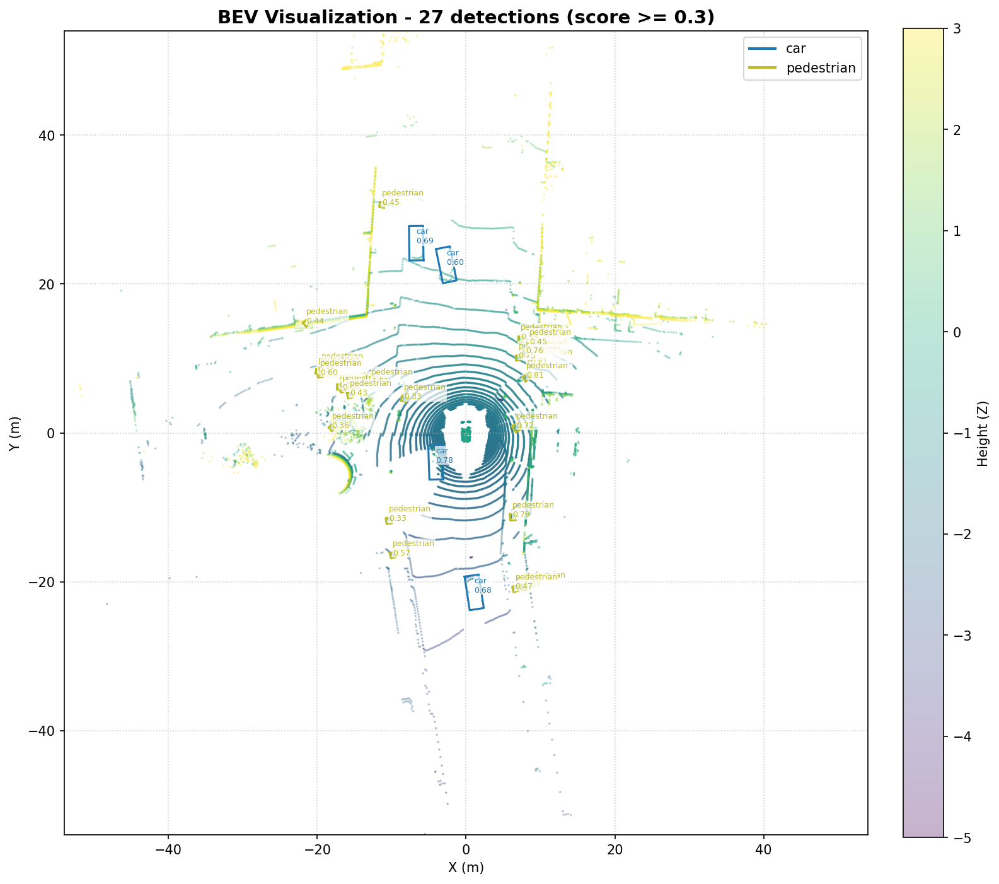


[8/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151607048933.pcd.bin.png


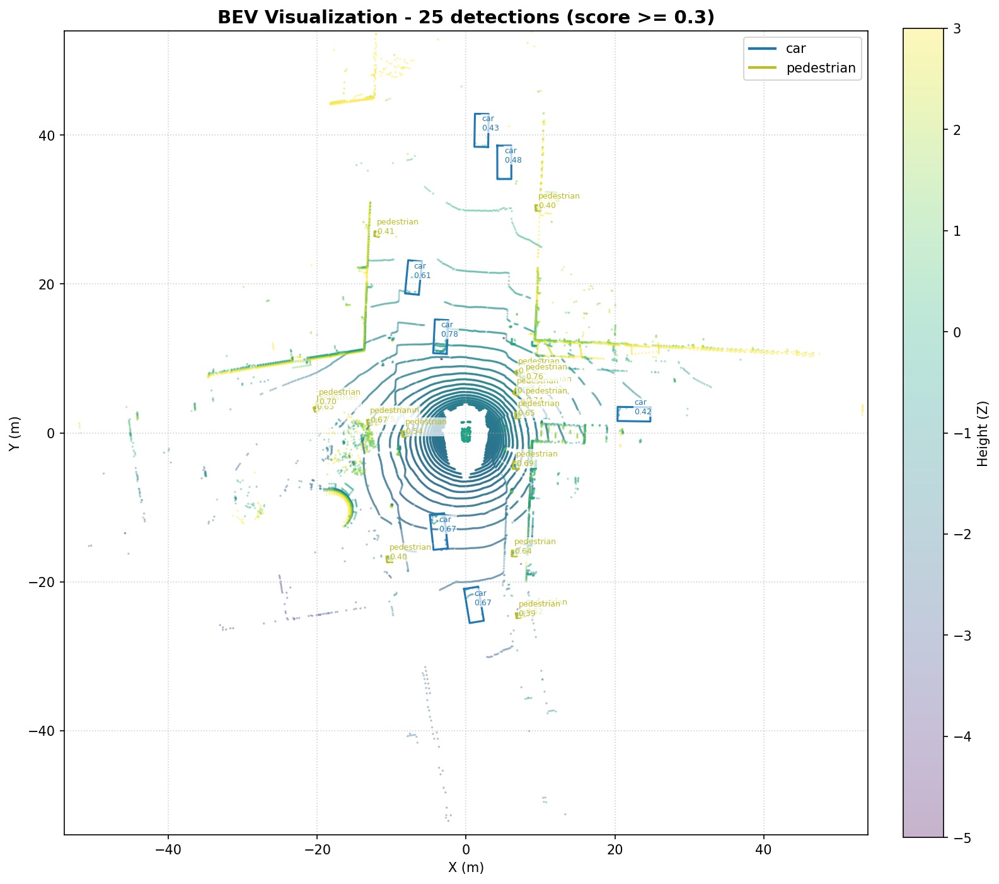


[9/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151607548824.pcd.bin.png


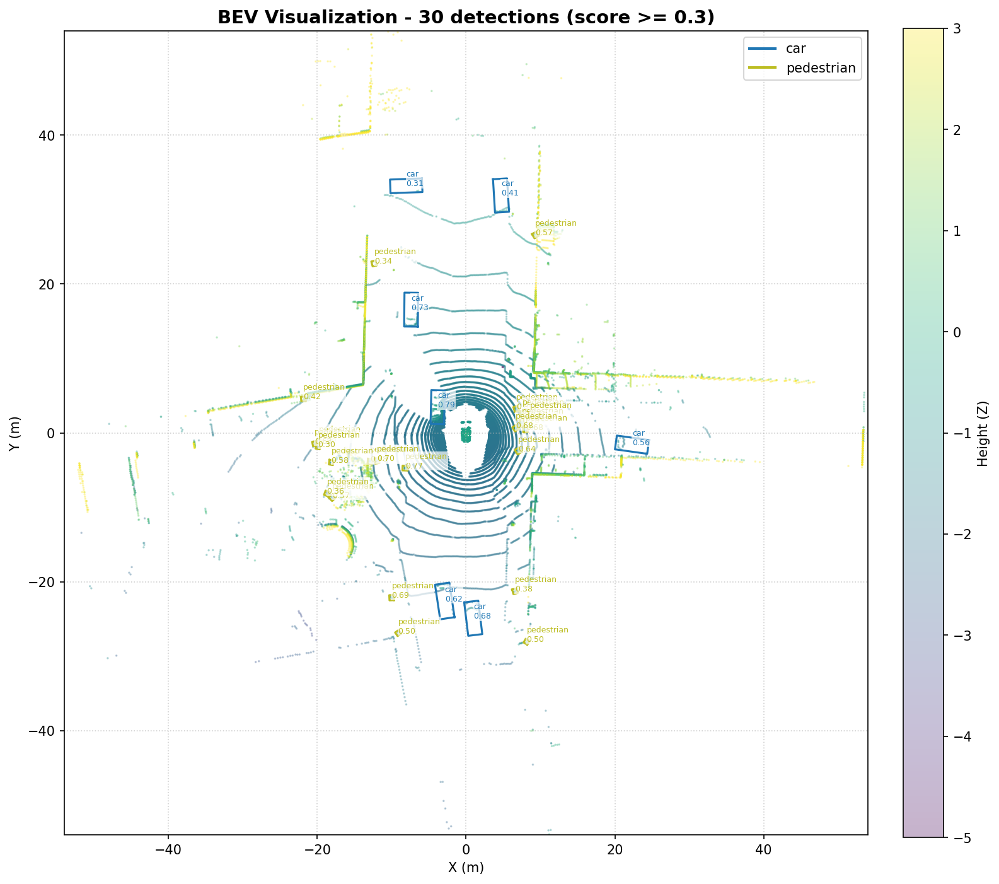


[10/10] File: n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151608048151.pcd.bin.png


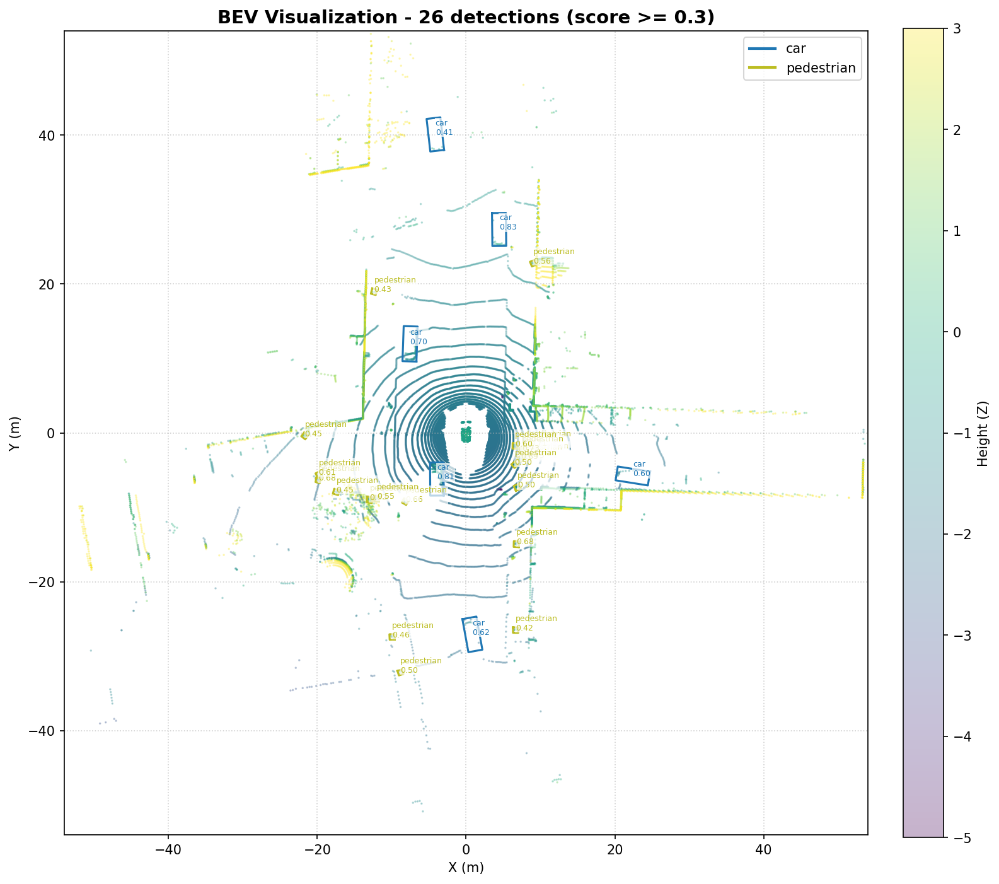

In [25]:
import os
import glob
from IPython.display import display, Image

vis_dir = "/content/3D-LiDAR-BEVFusion-MMDetection3D-V2/demo/outputs/vis"
image_paths = sorted(glob.glob(os.path.join(vis_dir, "*.png")))

if not image_paths:
    print(f"Không tìm thấy hình ảnh nào trong thư mục: {vis_dir}")
else:
    print(f"Tìm thấy {len(image_paths)} hình ảnh kết quả. Bắt đầu hiển thị:")
    for i, img_path in enumerate(image_paths, 1):
        print(f"\n[{i}/{len(image_paths)}] File: {os.path.basename(img_path)}")
        display(Image(filename=img_path, width=800))

In [ ]:
# import os
# import shutil
# from google.colab import files

# # Khai báo đường dẫn
# demo_dir = "/content/3D-LiDAR-BEVFusion-MMDetection3D-V2/demo"
# preds_dir = os.path.join(demo_dir, "outputs", "preds")
# out_vis_dir = os.path.join(demo_dir, "outputs", "vis")

# # Tạo thư mục tạm để chứa cả 2 thư mục con trước khi nén
# temp_zip_dir = "/content/bevfusion_outputs"
# os.makedirs(temp_zip_dir, exist_ok=True)

# # Copy dữ liệu vào thư mục tạm
# if os.path.exists(preds_dir):
#     shutil.copytree(preds_dir, os.path.join(temp_zip_dir, "preds"), dirs_exist_ok=True)
# if os.path.exists(out_vis_dir):
#     shutil.copytree(out_vis_dir, os.path.join(temp_zip_dir, "vis"), dirs_exist_ok=True)

# # Nén thư mục tạm thành file zip tại root dir
# zip_path = "/content/bevfusion_results"
# shutil.make_archive(zip_path, 'zip', temp_zip_dir)

# # Xóa thư mục tạm thời
# shutil.rmtree(temp_zip_dir)

# print(f"Đã nén thành công tại: {zip_path}.zip")

# # Thực hiện tải file về máy khách
# files.download(f"{zip_path}.zip")

Đã nén thành công tại: /content/bevfusion_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. 🌐 nuScenes Mini Dataset Setup (360° Surround Cameras + LiDAR)
Download and unpack the complete nuScenes v1.0-mini dataset (~1.7 GB) providing 10 continuous scenes with synchronized 6-camera surround vision and 32-beam LiDAR.

In [26]:
# ==================== BƯỚC 1: Tải và giải nén nuScenes Mini ====================
print("Đang tải và giải nén bộ dữ liệu nuScenes Mini (khoảng 1.7 GB)... (Quá trình này mất khoảng vài chục giây)")
!mkdir -p data/nuscenes
!wget -c -q --show-progress https://www.nuscenes.org/data/v1.0-mini.tgz -P data/
!tar -xzf data/v1.0-mini.tgz -C data/nuscenes

# Tạo liên kết tượng trưng (symlink) để các script tìm thấy dữ liệu
!ln -sf /content/3D-LiDAR-BEVFusion-MMDetection3D-V2/data/nuscenes /content/3D-LiDAR-BEVFusion-MMDetection3D-V2/data/v1.0-mini
print("Bước 1 hoàn tất: Đã sẵn sàng dữ liệu nuScenes Mini!\n")

Đang tải và giải nén bộ dữ liệu nuScenes Mini (khoảng 1.7 GB)... (Quá trình này mất khoảng vài chục giây)
v1.0-mini.tgz       100%[===================>]   3.88G   212MB/s    in 21s     
Bước 1 hoàn tất: Đã sẵn sàng dữ liệu nuScenes Mini!



In [27]:
# ==================== BƯỚC 2: Chạy script tạo ảnh GIF 360° ====================
print("Đang tiến hành chạy script tạo ảnh động GIF (Camera + BEV Radar)...")
!pixi run python visualize_nuscenes_mini_gif.py
print("Bước 2 hoàn tất: Đã tạo xong file GIF kết quả!\n")

Đang tiến hành chạy script tạo ảnh động GIF (Camera + BEV Radar)...
nuScenes Mini: 360-Degree Surround 6 Cameras + BEV LiDAR GIF Generator
Using dataset from: /content/3D-LiDAR-BEVFusion-MMDetection3D-V2/data/nuscenes/samples
Loaded 404 images for CAM_FRONT_LEFT
Loaded 404 images for CAM_FRONT
Loaded 404 images for CAM_FRONT_RIGHT
Loaded 404 images for CAM_BACK_LEFT
Loaded 404 images for CAM_BACK
Loaded 404 images for CAM_BACK_RIGHT

Processing 10 LiDAR frames...
  -> Generated Dashboard Frame 01/10: frame_01.png
  -> Generated Dashboard Frame 02/10: frame_02.png
  -> Generated Dashboard Frame 03/10: frame_03.png
  -> Generated Dashboard Frame 04/10: frame_04.png
  -> Generated Dashboard Frame 05/10: frame_05.png
  -> Generated Dashboard Frame 06/10: frame_06.png
  -> Generated Dashboard Frame 07/10: frame_07.png
  -> Generated Dashboard Frame 08/10: frame_08.png
  -> Generated Dashboard Frame 09/10: frame_09.png
  -> Generated Dashboard Frame 10/10: frame_10.png
SUCCESS! Animated 360-

--- [3] Dashboard Xe Tự Hành Động (6 Camera + Bản đồ BEV Radar) ---


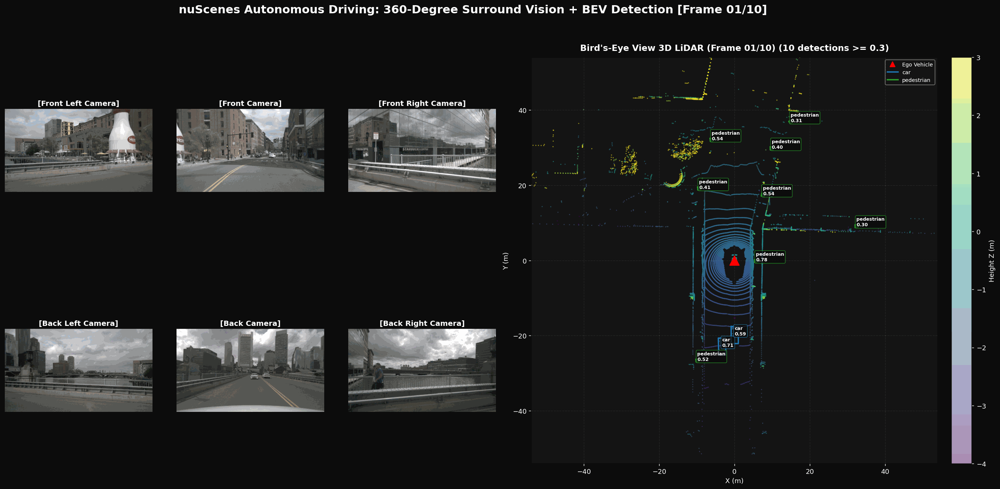

In [28]:

# ==================== BƯỚC 3: Hiển thị ảnh GIF trên Colab ====================
print("--- [3] Dashboard Xe Tự Hành Động (6 Camera + Bản đồ BEV Radar) ---")
import os
from IPython.display import Image, display

gif_file = "demo/outputs/nuscenes_mini_gif/nuscenes_360_surround_bev_animation.gif"
if os.path.exists(gif_file):
    display(Image(filename=gif_file, width=1100))
else:
    print(f"Lỗi: Không tìm thấy file GIF tại: {gif_file}. Vui lòng kiểm tra lại log chạy script ở trên.")

In [ ]:
# import os

# def print_full_tree(startpath, max_files_per_dir=3):
#     print(f"📁 {os.path.basename(startpath.rstrip('/'))}/")
#     for root, dirs, files in os.walk(startpath):
#         # Tính độ sâu thư mục
#         level = root.replace(startpath, '').count(os.sep)
#         indent = '│   ' * level
#         sub_indent = '│   ' * (level + 1)

#         # Hiển thị tên thư mục hiện tại nếu không phải gốc
#         if root != startpath:
#             print(f"{indent}├── 📁 {os.path.basename(root)}/")

#         # Sắp xếp các file để in ra thứ tự
#         files.sort()
#         num_files = len(files)

#         # Giới hạn hiển thị tối đa 3 file tượng trưng theo yêu cầu
#         display_files = files[:max_files_per_dir]
#         for f in display_files:
#             if f.startswith('.'):
#                 continue
#             print(f"{sub_indent}├── 📄 {f}")

#         if num_files > max_files_per_dir:
#             print(f"{sub_indent}└── ... và {num_files - max_files_per_dir} tệp tin khác.")

# nuscenes_path = "data/nuscenes"
# if os.path.exists(nuscenes_path):
#     print_full_tree(nuscenes_path)
# else:
#     print(f"Thư mục '{nuscenes_path}' không tồn tại. Vui lòng kiểm tra lại.")

📁 nuscenes/
│   ├── 📁 samples/
│   │   ├── 📁 CAM_FRONT_LEFT/
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_FRONT_LEFT__1533151603504799.jpg
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_FRONT_LEFT__1533151604004799.jpg
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_FRONT_LEFT__1533151604504799.jpg
│   │   │   └── ... và 401 tệp tin khác.
│   │   ├── 📁 CAM_BACK_LEFT/
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_BACK_LEFT__1533151603547405.jpg
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_BACK_LEFT__1533151604047405.jpg
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_BACK_LEFT__1533151604547405.jpg
│   │   │   └── ... và 401 tệp tin khác.
│   │   ├── 📁 CAM_BACK_RIGHT/
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_BACK_RIGHT__1533151603528113.jpg
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_BACK_RIGHT__1533151604028370.jpg
│   │   │   ├── 📄 n008-2018-08-01-15-16-36-0400__CAM_BACK_RIGHT__1533151604528113.jpg
│   │   │   └── ... và 401 

## 10. 🎬 Full 404-Frame Batch Inference & Full HD Dashboard Video
Run high-throughput GPU inference across all 404 keyframes of nuScenes Mini using `run_inference_all.py` and compile a Full HD 1080p synchronized 6-camera + 3D BEV radar video.

In [ ]:
# ==================== BƯỚC 1: Chạy script tạo video 404 frame ====================
print("Đang chạy script tạo video toàn bộ 404 frames (chạy hoàn toàn ẩn, không ghi log)...")
!pixi run python run_inference_all.py > /dev/null 2>&1

In [31]:
!pixi run python create_full_nuscenes_video.py

nuScenes Mini FULL 404-Frame Video Generator (6 Surround Cameras + 3D BEV)
Loaded 404 images for CAM_FRONT_LEFT
Loaded 404 images for CAM_FRONT
Loaded 404 images for CAM_FRONT_RIGHT
Loaded 404 images for CAM_BACK_LEFT
Loaded 404 images for CAM_BACK
Loaded 404 images for CAM_BACK_RIGHT

Found total 404 LiDAR frames across nuScenes mini!

Rendering video frames (Fast OpenCV Engine)...
  Processed 020/404 frames (5.0%) - Speed: 6.9 fps
  Processed 040/404 frames (9.9%) - Speed: 7.1 fps
  Processed 060/404 frames (14.9%) - Speed: 7.4 fps
  Processed 080/404 frames (19.8%) - Speed: 6.6 fps
  Processed 100/404 frames (24.8%) - Speed: 6.5 fps
  Processed 120/404 frames (29.7%) - Speed: 6.7 fps
  Processed 140/404 frames (34.7%) - Speed: 6.9 fps
  Processed 160/404 frames (39.6%) - Speed: 7.0 fps
  Processed 180/404 frames (44.6%) - Speed: 6.7 fps
  Processed 200/404 frames (49.5%) - Speed: 6.6 fps
  Processed 220/404 frames (54.5%) - Speed: 6.7 fps
  Processed 240/404 frames (59.4%) - Speed: 

In [32]:

# ==================== BƯỚC 2: Xem video trực tiếp trên Colab ====================
import os
from IPython.display import HTML
from base64 import b64encode

video_path = "demo/outputs/full_video/nuscenes_full_360_bev.mp4"

if os.path.exists(video_path):
    print("\nHiển thị trình phát video:")
    # Đọc tệp video và chuyển đổi sang định dạng base64 để nhúng vào HTML
    mp4 = open(video_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

    # Hiển thị trình phát video HTML5 chất lượng cao
    display(HTML(f"""
    <video width="900" controls style="border: 1px solid #ddd; border-radius: 8px; box-shadow: 0 4px 8px rgba(0,0,0,0.1);">
        <source src="{data_url}" type="video/mp4">
        Trình duyệt của bạn không hỗ trợ thẻ video HTML5.
    </video>
    """))
else:
    print(f"\nLỗi: Không tìm thấy tệp video tại '{video_path}'. Vui lòng kiểm tra lại log lỗi phía trên.")


Hiển thị trình phát video:
